# Praktikum 1: ilustrasi SVM linier

In [1]:
# Langkah 1 - Import Library

# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

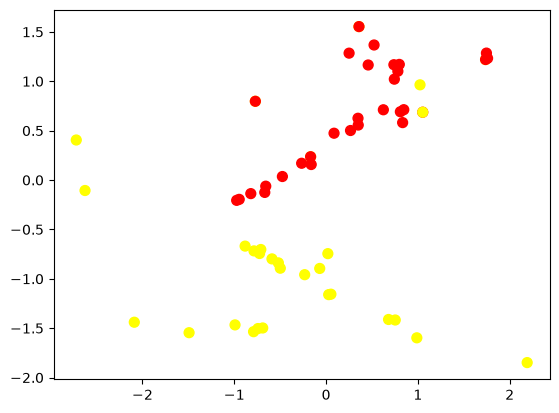

In [2]:
# Langkah 2 - Memuat data PBL
import pandas as pd
from sklearn.preprocessing import StandardScaler
data = pd.read_csv('../../dataset_pbl/cafes.csv')
data = data[data['source_query'].isin(['Cafe Soekarno Hatta Malang', 'Cafe Dinoyo Malang'])]
data = data.sample(frac=1, random_state=42).reset_index(drop=True)
X = StandardScaler().fit_transform(data[['latitude', 'longitude']])
y = data['source_query'].map({'Cafe Soekarno Hatta Malang': 0, 'Cafe Dinoyo Malang': 1}).to_numpy()
plt.scatter(X[:,0], X[:,1], c=y, s=50, cmap='autumn')

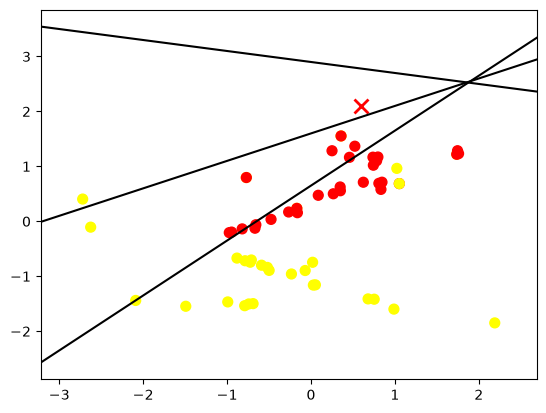

In [3]:
# Langkah 3 - Buat Ilustrasi Garis Pemisah

# 1. Plot scatter dari Langkah 2
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# 2. Tambahkan titik data baru berbentu 'x' merah
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

# 3. Buat deret nilai X untuk menggambar garis
xfit = np.linspace(X[:,0].min()-0.5, X[:,0].max()+0.5)

# 4. Gambar ketiga garis pemisah (format tuple: m = slope, b = intercept)
for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

# 5. Atur batas tampilan sumbu X
plt.xlim(X[:,0].min()-0.5, X[:,0].max()+0.5)
plt.show()

(-3.2206074257076978, 2.690251094319831)

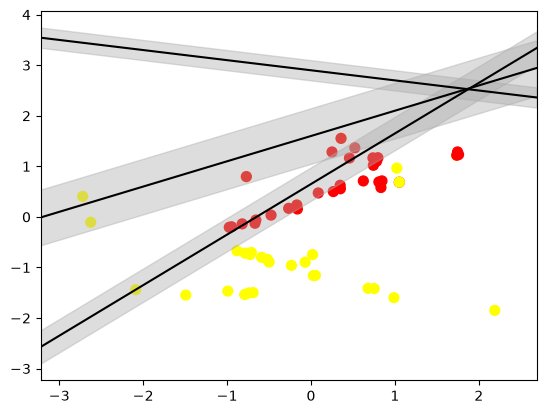

In [4]:
# Langkah 4 - Ilustrasi Margin

xfit = np.linspace(X[:,0].min()-0.5, X[:,0].max()+0.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(X[:,0].min()-0.5, X[:,0].max()+0.5)

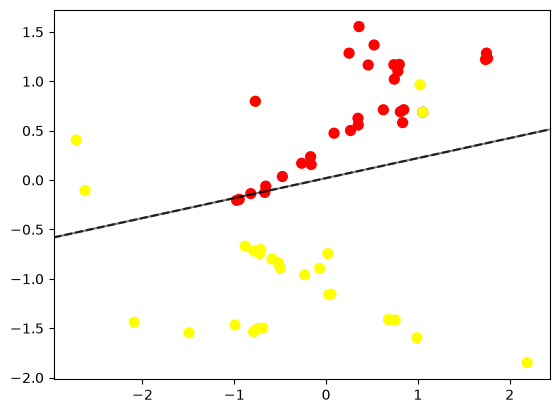

In [5]:
# Langkah 5 - Fitting Model

from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

# Selanjutnya buat fungsi untuk membantu visualisasi hasil fit model.
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):
    
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)
    
    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])
    
    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

# Lakukan plotting dengan fungsi yang telah dibuat.
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)

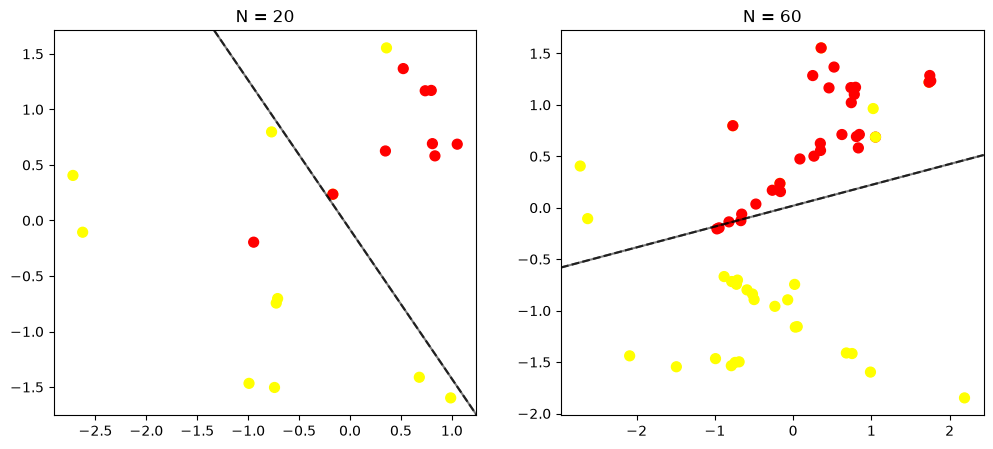

In [6]:
# Membandingkan jumlah sampel
def plot_svm(N=10, ax=None):
    subset, labels = X[:N], y[:N]
    model = SVC(kernel='linear', C=1E10).fit(subset, labels)
    ax = ax or plt.gca()
    ax.scatter(subset[:,0], subset[:,1], c=labels, s=50, cmap='autumn')
    plot_svc_decision_function(model, ax)

fig, axes = plt.subplots(1, 2, figsize=(12,5))
for ax, N in zip(axes, [20, 60]):
    plot_svm(N, ax)
    ax.set_title(f'N = {N}')

In [7]:
from ipywidgets import interact, fixed
interact(plot_svm, N=[10,60], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 60), value=10), Output()), _dom_classes=('widget-…

<function __main__.plot_svm(N=10, ax=None)>